This notebook takes images that contain the beginning of continuous-readout mode streaks and adjusts their wcs to be accurate.

It does this by extracting a list of star positions from the beginning of streaks and using astrometry.net to match this to known star positions.

Unfortunately, on Google Colab, there are several setup steps you must do to get this ready to use, and you'll have to do it every time. I have not been successful at installing astrometry.net outside of colab, but doing so would streamline the process.

In [1]:
#first install this
!sudo apt install astrometry.net


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  fonts-droid-fallback fonts-noto-mono fonts-urw-base35 ghostscript
  javascript-common libastrometry0 libcfitsio-bin liberfa1 libfftw3-single3
  libgs9 libgs9-common libgsl27 libgslcblas0 libidn12 libijs-0.35
  libimagequant0 libjbig2dec0 libjs-jquery-datatables libjs-jquery-hotkeys
  libjs-jquery-isonscreen libjs-jquery-metadata libjs-jquery-tablesorter
  libjs-jquery-throttle-debounce liblbfgsb0 libnetpbm10 libraqm0 libwcs7
  libxsimd-dev netpbm poppler-data python3-astrometry python3-astropy
  python3-attr python3-beniget python3-click python3-colorama
  python3-configobj python3-cov-core python3-coverage python3-dateutil
  python3-decorator python3-erfa python3-exif python3-exifread python3-gast
  python3-hypothesis python3-iniconfig python3-nose2 python3-numpy
  python3-olefile python3-packaging python3-pil python3-pluggy python3-pl

In [2]:
#to check that it worked, run this command and it should output '/usr/bin/solve-field'
!which solve-field

/usr/bin/solve-field


In [3]:
#you have to either downgrade numpy or go in to the astrometry.net files and adjust
#some code; downgrading is simpler
#it will prompt you to restart runtime after this, which is fine
!pip install "numpy<1.24"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 82.1 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
blosc2 3.2.0 requires numpy>=1.26, but you have numpy 1.23.5 which is incompatible.
scikit-image 0.25.2 requires numpy>=1.24, but you have numpy 1.23.5 which is incompatible.
bigframes 1.38.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
imbalanced-learn 0.13.0 requires numpy<3,>=1.24.3, but you have numpy 1.23.5 which is incompatible.
albucore 0.0.23 requires numpy>=1.24.4, but you have numpy 1.23.5 which is incompatible.
albumentations 2.0.5 requires numpy>=1.24.4, but you have numpy 1.23.5 which is incompatible.
treescope 0.1.9 requires numpy>=1.25.2, but you

one more thing: go to this website:

http://data.astrometry.net/4100/

and download the following:

index-4107.fits                                    
index-4108.fits                                    
index-4109.fits                                    
index-4110.fits

then, upload them to /usr/share/astrometry/

(you can get to it through the folder buttons (start with the folder '..') and then drag and drop them inside)

also, upload the file(s) that you want to work on in this session, and put them in /content (which is your default directory). for example, i used ztf_20221020163819_000640_zg_c01_x.fits.fz

In [14]:
filepath = '/content/ztf_20221020163819_000640_zg_c01_x.fits.fz'
#for now, we're only using one extension of the fits file
#although it can easily be done for all of them
#we'll set that variable here as well
quad = 1

In [21]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import subprocess
from astropy.wcs import WCS

In [2]:
#matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

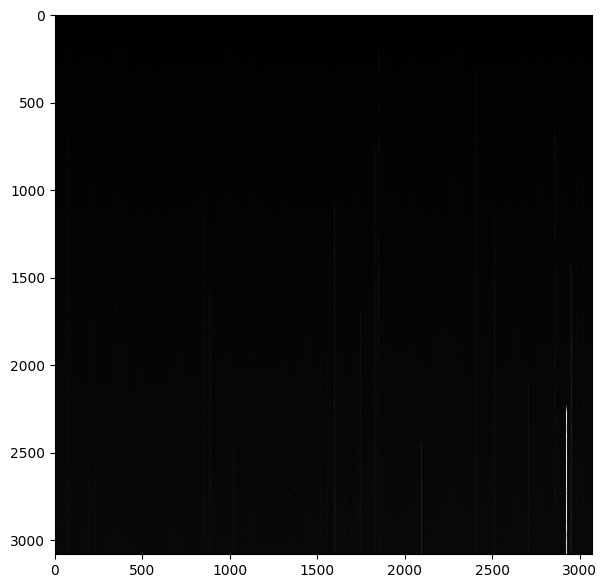

In [8]:
#let's look at our image
hdul_start = fits.open(filepath)
array = hdul_start[quad].data
plt.imshow(np.sqrt(hdul_start[quad].data))


In [9]:
'''
Now we're going to calculate where the beginnings of the brightest streaks are.
To do this, we take the rolling mean along each column
and see when it changes by >70 over a different of ~100 pixels
(both of these parameters can be adjusted, but these ones work for me)

and it keeps the position of the greatest change
note that pixels separated by <8 are considered to be part of the same streak
note too that in the case of overlapping streaks, only the brighter one is retained
(this is because the inherent variability of some streaks is quite high,
and allowing more than one position along each streak meant that there were
too many which were clearly not from new stars)

this cell will take a while to run
'''

diffs = []
for x_coord in range(np.shape(array)[1]):
    if quad==1 or quad==2: #moving from top to bottom if we have quad 1 or 2
      columns = range(0, np.shape(array)[0]-220)
    elif quad==3 or quad==4: #moving from bottom to top if we have quad 3 or 4
      columns = range(np.shape(array)[0]-220, 0, -1)
    for i in columns:
        mean_1 = np.mean(array[i:i+100,x_coord])
        mean_2 = np.mean(array[i+120:i+220,x_coord])
        if quad==1 or quad==2:
          diff = mean_2-mean_1
        else:
          diff = mean_1-mean_2
        if diff>30: #diff>100 did not give us enough stars for astrometry.net to be confident
            if len(diffs)>0:
                last_x_coord = diffs[-1][0]
                last_y_coord = diffs[-1][1]
                last_diff = diffs[-1][2]
                if np.abs(x_coord-last_x_coord) < 8:
                    # if np.abs((i+40)-last_y_coord) > 100 and diff>last_diff: #new star starting partway
                    #     diffs.append(np.array((x_coord,i+100, diff)))
                    # else:
                    if last_diff < diff:
                        diffs[-1]=np.array((x_coord,i+100, diff)) #replace if this is just a brighter version of the last one
                    else: #if the last one was brighter and they're the same, just ignore this one
                        continue
                else:
                    diffs.append(np.array((x_coord,i+100, diff)))
            else:
                diffs.append(np.array((x_coord,i+100, diff)))
        continue

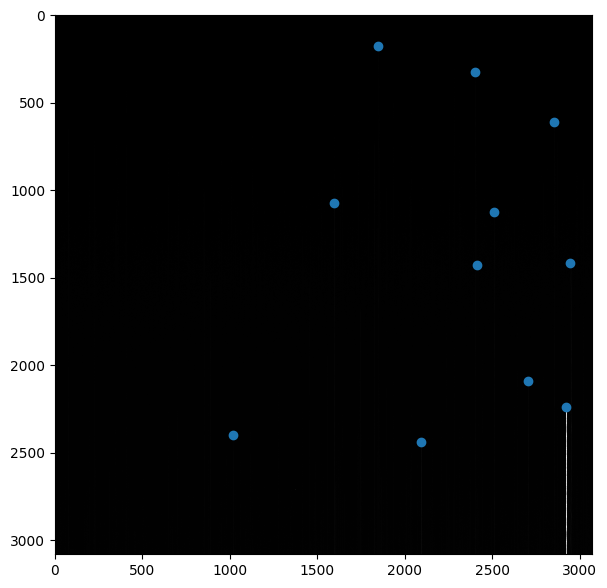

In [10]:
#let's make sure that worked
#this should have the positions of the beginnings of streaks overplotted
#on the original image
plt.imshow(array)
plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])

In [11]:
#we have to convert this into a fits bintable file

def write_xylist(diffs, output_file):
    """
    Writes an XY list file from a given star catalog.
    """
    diffs = np.array(diffs)
    sorted_arr = diffs[diffs[:, 2].argsort()[::-1]]

    # Create FITS columns
    col1 = fits.Column(name='X', format='D', array=sorted_arr[:, 0])
    col2 = fits.Column(name='Y', format='D', array=sorted_arr[:, 1])

    # Create a FITS BINTABLE
    cols = fits.ColDefs([col1, col2])
    hdu = fits.BinTableHDU.from_columns(cols)

  # Save to a FITS file
    hdu.writeto(output_file+'.fits', overwrite=True)
    print(f"XY list saved to {output_file}.fits")

In [12]:
def run_solve_field(xy_file, image_width, image_height, scale_low, scale_high):
    """
    Runs Astrometry.net's solve-field with an XY list file.

    Parameters:
    xy_file (str): Path to the XY list file.
    image_width (int): Width of the original image.
    image_height (int): Height of the original image.
    scale_low (float): Lower bound of scale in arcsec/pixel.
    scale_high (float): Upper bound of scale in arcsec/pixel.
    """
    cmd = [
        "solve-field", xy_file,
        "--x-column", "X", "--y-column", "Y",
        "--width", str(image_width), "--height", str(image_height),
        "--scale-units", "arcsecperpix",
        "--scale-low", str(scale_low), "--scale-high", str(scale_high),
        "--overwrite",
        '--no-verify',
        '--ra', str(RA),
        '--dec', str(DEC),
        '--radius',str(5)
    ]

    print("Running solve-field...")
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    print(result.stderr)

In [15]:
#here is where we do all the stuff


xy_file = "stars" #you can give this a more descriptive name
write_xylist(diffs, xy_file)

# Set parameters
image_width, image_height = np.shape(array)[1],np.shape(array)[0]
scale_low, scale_high = hdul_start[0].header['PIXSCALX']-.1,hdul_start[0].header['PIXSCALX']+.1

#calculating an initial guess for the ra and dec based off the crpix and crvals
xoffset = 1540 - hdul_start[quad].header['CRPIX1']
yoffset = 1540 - hdul_start[quad].header['CRPIX2']
RA = hdul_start[quad].header['CRVAL1'] + (hdul_start[quad].header['CD1_1']*xoffset + hdul_start[quad].header['CD1_2']*yoffset)
DEC = hdul_start[quad].header['CRVAL2'] + (hdul_start[quad].header['CD2_1']*xoffset + hdul_start[quad].header['CD2_2']*yoffset)


run_solve_field(xy_file+'.fits', image_width, image_height, scale_low, scale_high)

XY list saved to stars.fits
Running solve-field...
Reading input file 1 of 1: "stars.fits"...
solve-field.c:327:plot_source_overlay Plotting command failed
 solve-field.c:133:run_command Command was: "/usr/bin/plotxy -I /tmp/tmp.ppm.xtHPUP -i ./stars.axy -X X -Y Y -C red -w 2 -N 50 -x 1 -y 1 -P | /usr/bin/plotxy -i ./stars.axy -X X -Y Y -I - -w 2 -r 3 -C red -n 50 -N 200 -x 1 -y 1 > ./stars-objs.png"

 solve-field.c:132:run_command Command exited with exit status 1
Solving...
Reading file "./stars.axy"...
Only searching for solutions within 5 degrees of RA,Dec (303.971,23.7111)
Field 1 did not solve (index index-4110.fits, field objects 1-10).
Field 1 did not solve (index index-4109.fits, field objects 1-10).
Field 1 did not solve (index index-4108.fits, field objects 1-10).
  log-odds ratio 47.7687 (5.56783e+20), 7 match, 0 conflict, 0 distractors, 50 index.
  RA,Dec = (304.307,23.6937), pixel scale 1.01263 arcsec/pix.
  Hit/miss:   Hit/miss: +++++++(best)++++
Field 1: solved with ind

In [ ]:
#this will output a bunch of stuff, and if it works it will make files
#the .wcs file is the updated coordinate system

In [17]:
new_wcs = fits.open('/content/stars.wcs')

In [18]:
#we can look at it here

# new_wcs.info()
new_wcs[0].header

SIMPLE  =                    T / Standard FITS file                             
BITPIX  =                    8 / ASCII or bytes array                           
NAXIS   =                    0 / Minimal header                                 
EXTEND  =                    T / There may be FITS ext                          
WCSAXES =                    2 / no comment                                     
CTYPE1  = 'RA---TAN-SIP' / TAN (gnomic) projection + SIP distortions            
CTYPE2  = 'DEC--TAN-SIP' / TAN (gnomic) projection + SIP distortions            
EQUINOX =               2000.0 / Equatorial coordinates definition (yr)         
LONPOLE =                180.0 / no comment                                     
LATPOLE =                  0.0 / no comment                                     
CRVAL1  =        304.042865488 / RA  of reference point                         
CRVAL2  =        23.6310003213 / DEC of reference point                         
CRPIX1  =              2388.

In [19]:
#we can compare it to the original header
hdul_start[quad].header

XTENSION= 'IMAGE   '           / IMAGE extension                                
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 3072 / length of data axis 1                          
NAXIS2  =                 3080 / length of data axis 2                          
PCOUNT  =                    0 / required keyword; must = 0                     
GCOUNT  =                    1 / required keyword; must = 1                     
EXTNAME = '1       '                                                            
HDUVERS =                    1                                                  
CCD_ID  =                    1 / ID value of CCD detector                       
CCDNAME = 'S01     '           / Detector name or serial number                 
AMP_ID  =                    0 / ID value of CCD amplifier                      
AMP_NAME= 'H       '        

In [27]:
#here we combine them!

# Open your original FITS file
original_fits = fits.open('/content/ztf_20221020163819_000640_zg_c01_x.fits.fz', mode='update')

# Load the WCS information from your .wcs file
wcs_header = fits.open('stars.wcs')[0].header

# Access the original FITS header
original_header = original_fits[quad].header

# Iterate through the WCS header and update the original header
for card in wcs_header.cards:
    keyword = card.keyword
    # If the keyword already exists in the original header, update its value
    if keyword in original_header:
        original_header[keyword] = card.value  # Update the value of the existing card
    else:
        original_header.append(card)  # Add the new card if it doesn't exist

# Save the updated FITS file
original_fits.flush()
# original_fits.close()

 [astropy.io.fits.verify]



In [30]:
#check and make sure it worked
new_hdul = fits.open('/content/ztf_20221020163819_000640_zg_c01_x.fits.fz')

In [31]:
new_hdul[quad].header

SIMPLE  =                    T / Standard FITS file                             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 3072 / length of data axis 1                          
NAXIS2  =                 3080 / length of data axis 2                          
EXTNAME = '1       '           / name of this binary table extension            
HDUVERS =                    1                                                  
CCD_ID  =                    1 / ID value of CCD detector                       
CCDNAME = 'S01     '           / Detector name or serial number                 
AMP_ID  =                    0 / ID value of CCD amplifier                      
AMP_NAME= 'H       '           / Name of CCD amplifier                          
GAIN    =                  6.1 / Gain e-/adu                                    
READNOI =                  9

Re-download your file from the google drive storage, and the coordinates have been fixed! (to within a couple pixels)

One other output we get is the .corr file, which reports the matches between the star catalogue we gave it and the star catalogue it matched to. I think that in order to do that you would take the index_id column and find the corresponding indexes in index-4107.fits (or whichever index file got the successful match), but I haven't done that yet.

In [32]:
hdul_corr = fits.open('/content/stars.corr')

In [35]:
hdul_corr[1].data

FITS_rec([(2920., 2237., 303.8759002 , 23.50980711, 2919.62962751, 2240.14132209, 303.87598752, 23.50892362, 46,  0, 0.99939765),
          (2946., 1413., 303.87489655, 23.74164438, 2945.80475855, 1411.68387626, 303.87496749, 23.74201417, 47,  1, 0.99982015),
          (2092., 2439., 304.12803315, 23.44596085, 2091.83992677, 2439.93208955, 304.12807417, 23.44569806, 49,  2, 0.99976359),
          (1848.,  176., 304.22336185, 24.08138885, 1848.10681081,  173.95762027, 304.22334832, 24.08196749, 15,  3, 0.99961424),
          (1595., 1071., 304.29282633, 23.82638326, 1595.00013563, 1073.12513684, 304.29280666, 23.82578333, 48,  4, 0.99970492),
          (2853.,  609., 303.91040257, 23.96744116, 2853.32091035,  609.50616235, 303.91029916, 23.96730001,  7,  5, 0.99980158),
          (1018., 2399., 304.45746886, 23.44669069, 1018.00568933, 2398.43813871, 304.45747221, 23.44684943,  1,  6, 0.99960702),
          (2508., 1121., 304.01196158, 23.82034775, 2507.52812376, 1122.12217813, 304.0120

In [ ]:
# index_hdul = fits.open('/content/index-4107.fits')

In [ ]:
# index_hdul.info()

Filename: /content/index-4107.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     105   ()      
  1                1 BinTableHDU     13   4454259R x 1C   [16A]   
  2                1 BinTableHDU    113   0R x 1C   [0A]   
  3                1 BinTableHDU     17   262144R x 1C   [4A]   
  4                1 BinTableHDU     22   262143R x 1C   [2A]   
  5                1 BinTableHDU     30   9R x 1C   [8A]   
  6                1 BinTableHDU     15   4454259R x 1C   [8A]   
  7                1 BinTableHDU     90   0R x 1C   [0A]   
  8                1 BinTableHDU     17   131072R x 1C   [4A]   
  9                1 BinTableHDU     22   131071R x 1C   [4A]   
 10                1 BinTableHDU     29   7R x 1C   [8A]   
 11                1 BinTableHDU     15   1909957R x 1C   [12A]   
 12                1 BinTableHDU     13   1909957R x 1C   [1B]   
 13                1 BinTableHDU     23   1909957R x 4C   [1E, 1E, 1E, 1E]   
